# MCDI505 · Semana 3 — Modelos avanzados (ARFIMA / GARCH)
**Estudiante:** Roberto Moncada · 
**Programa:** Magíster en Ciencia de Datos, UNAB Online
**Curso:** MCDI505, Unidad 3, Semana 3 · 
**Archivo:** `mcdi505_s3rmoncada.ipynb` · 
**Fecha:** Octubre de 2026

**Pregunta de la semana:** ¿la memoria larga o la volatilidad condicional aportan algo al SARIMA en esta serie? Una respuesta negativa bien fundamentada es tan válida como una positiva.

> 📝 Las celdas marcadas **[BORRADOR]** son un apoyo preparado con un asistente de IA. Las celdas **[AUTOR]** que van debajo son las que redacto yo con mis propias palabras. Antes de entregar, las celdas [BORRADOR] se eliminan o se reemplazan (ver la declaración de uso de IA al final).

## Hoja de decisiones

**[BORRADOR]**

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Memoria larga | **No hay memoria larga** en los residuos del SARIMA de la Semana 2. El H mayor que 0,5 se explica por el sesgo del método R/S cuando hay pocos datos. | Figura 1: la ACF de los 83 residuos no decae lentamente; solo el rezago 24 (−0,22) toca la banda de ±0,215. Ljung-Box p = 0,526 / 0,102 / 0,115 (rezagos 12, 24 y 36). Hurst (R/S) H = 0,652, es decir, d = 0,152. Figura 2: en 500 ruidos blancos de n = 83, el H promedio es 0,612 (IC 95 %: 0,392 a 0,823) y el 37 % supera 0,652. | Agregar un ARFIMA(0,d,0) con d = 0,152. | Se mantiene la diferenciación entera (d = 1 y D = 1) de la Semana 2. La corrección ARFIMA es casi nula (−0,24 GWh en promedio) y además empeora la validación (fila 3). |
| 2. Volatilidad | **No hay volatilidad condicional**: la varianza de los residuos se puede suponer constante. | Figura 3: la ACF de los residuos² no muestra agrupamiento. Ljung-Box sobre residuos² p = 0,485; ARCH-LM (12) p = 0,639, el mismo valor de la Semana 2. GARCH(1,1): ω = 0,457, α = 0,066, β = 0,442, persistencia α + β = 0,509 (converge y cumple α + β < 1). Residuos estandarizados por σ̂ₜ: Ljung-Box² p = 0,654 y ARCH-LM p = 0,832. | Construir los intervalos con la varianza condicional de un GARCH(1,1). | Se mantienen los intervalos del SARIMA con varianza constante. Las bandas GARCH vuelven a la varianza incondicional en 2 o 3 meses (factor de 0,96 a 1,00). |
| 3. Contraste con el modelo clásico | **Ninguna de las dos extensiones mejora al SARIMA** en la validación 2023. | Tabla 1 (GWh): RMSE / MAE del SARIMA = 7,13 / 6,68; SARIMA + ARFIMA = 7,34 / 6,93; naive estacional = 7,26 / 6,53. Tabla 2: cobertura del IC 95 % de 12/12 en ambos; ancho medio de 29,4 GWh (SARIMA) y 29,3 GWh (GARCH). Los 12 errores del SARIMA son positivos (sesgo de +6,68 GWh). | Decir que hay mejora por diferencias de RMSE menores a 0,3 GWh o por bandas 0,4 % más angostas. | Las diferencias son de alrededor del 3 % del error de un mes y no se pueden separar del azar con 12 meses. El problema real del pronóstico es el sesgo de nivel. |
| 4. Selección del modelo | **Se mantiene el modelo B de la Semana 2: SARIMA(0,1,1)(0,1,1)₁₂ con covid**, sobre el logaritmo del consumo. | Bloques 1 a 3: sin memoria larga (H dentro de lo esperado para ruido blanco), sin efectos ARCH (p = 0,639) y sin mejora en el pronóstico (ΔRMSE ARFIMA = +0,21 GWh; misma cobertura). AIC = −300,9, igual que en la Semana 2. | SARIMA + ARFIMA(0,d,0) y SARIMA con bandas GARCH(1,1). | En la Semana 4 se reestima este SARIMA con 2015-2023 y se pronostica 2024. Hay que vigilar el sesgo de nivel de 2023 y el MA estacional, que está en el límite de invertibilidad (−0,981). |

**[AUTOR] Hoja de decisiones** _(completar con mis propias palabras a partir del borrador anterior)_

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Memoria larga | | | | |
| 2. Volatilidad | | | | |
| 3. Contraste con el modelo clásico | | | | |
| 4. Selección del modelo | | | | |

## 0. Configuración, datos y punto de partida

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

In [2]:
# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# No necesita modificarlas.
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
df = pd.read_csv("consumo_electrico_litoral_depurado.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Partición oficial: entrenamiento 2015-2022, validación 2023. 2024 no se utiliza esta semana.
H = 12
log_train, log_val = log_y[:"2022-12"], log_y["2023-01":"2023-12"]
y_val = y["2023-01":"2023-12"]
print(f"Entrenamiento: {len(log_train)} meses | Validación: {len(log_val)} meses")

Entrenamiento: 96 meses | Validación: 12 meses


In [4]:
# ==============================================================================
# COMPLETE: el modelo SARIMA que seleccionó en la Sumativa 2 (misma especificación)
# ==============================================================================
# Sumativa 2: logaritmo, d = 1 y D = 1 (ADF + KPSS + ACF(12)); se eligió el modelo B (tipo «airline»)
# por puntaje AIC/BIC/RMSE y MAE con origen móvil, entre los candidatos que pasaron Ljung-Box (12 y 24).
ORDEN = (0, 1, 1)                  # (p, d, q)
ORDEN_ESTACIONAL = (0, 1, 1, 12)   # (P, D, Q, s)
USAR_COVID = True                  # indicador covid (mar-2020 a dic-2021) como regresor, igual que en la Sumativa 2

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

In [5]:
# Reestimación del SARIMA sobre el entrenamiento (escala logarítmica)
X_train = df[["covid"]][:"2022-12"] if USAR_COVID else None
X_val = df[["covid"]].loc["2023-01":"2023-12"] if USAR_COVID else None

sarima = SARIMAX(log_train, exog=X_train, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]      # se descartan las primeras d + D·s observaciones
residuos = sarima.resid.iloc[inicio:]

pron = sarima.get_forecast(H, exog=X_val)
media_log = pron.predicted_mean
ic_log = pron.conf_int(alpha=0.05)
sd_log = (ic_log.iloc[:, 1] - media_log) / 1.96

naive = y["2022-01":"2022-12"].to_numpy()                          # naive estacional
print(f"AIC = {sarima.aic:.1f} | residuos utilizables: {len(residuos)}")
print(sarima.summary().tables[1])
print(f"Efecto covid: {100 * (np.exp(sarima.params['covid']) - 1):.1f} % | "
      f"mín. |raíz MA| = {np.abs(sarima.maroots).min():.3f} (1 = frontera de invertibilidad)")

AIC = -300.9 | residuos utilizables: 83
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid         -0.0617      0.017     -3.629      0.000      -0.095      -0.028
ma.L1         -0.2050      0.086     -2.395      0.017      -0.373      -0.037
ma.S.L12      -0.9808      2.244     -0.437      0.662      -5.378       3.417
sigma2         0.0011      0.002      0.461      0.645      -0.003       0.006
Efecto covid: -6.0 % | mín. |raíz MA| = 1.002 (1 = frontera de invertibilidad)


**[BORRADOR] Punto de partida.** Parto del modelo que elegí en la Sumativa 2: el **SARIMA(0,1,1)(0,1,1)₁₂ con la variable covid** (modelo B, tipo «airline»), estimado sobre el logaritmo del consumo con entrenamiento 2015-2022. Al reestimarlo aquí obtengo el mismo AIC que en la Semana 2 (−300,9) y el mismo efecto del COVID-19 (−6,0 %), por lo que es la misma especificación. El MA estacional sigue en el límite de invertibilidad (−0,981), igual que en la Semana 2 (Box et al., 2015). Las primeras d + D·s = 13 observaciones se descartan, así que trabajo con 83 residuos. Como pide la guía, todo el diagnóstico de esta semana se hace sobre estos residuos y no sobre la serie original.

**[AUTOR] Punto de partida**

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## 1. Modelamiento de memoria larga (ARFIMA / diferenciación fraccional)

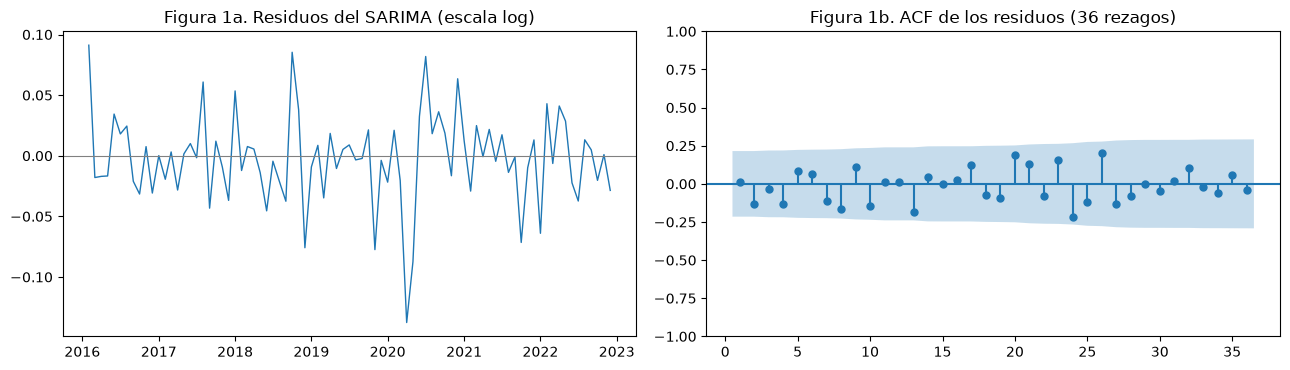

Banda ±1,96/√n = ±0.215 | rezagos fuera de la banda: [24]
Ljung–Box sobre los residuos:
    lb_stat  lb_pvalue
12   11.034      0.526
24   33.085      0.102
36   46.410      0.115

Hurst (R/S) = 0.652  ->  d = 0.152


Ruido blanco, n = 83: H medio = 0.612 | IC 95 % = [0.392, 0.823] | P(H_ruido >= H_res) = 0.37


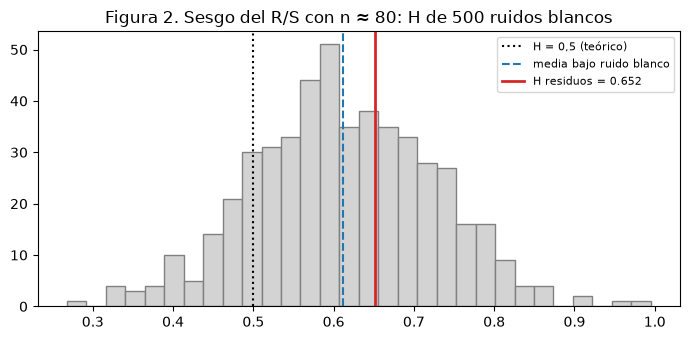


Corrección ARFIMA en log (h = 1..12): [-0.0055 -0.0036 -0.0028 -0.0024 -0.0021 -0.0019 -0.0017 -0.0016 -0.0015
 -0.0014 -0.0013 -0.0013]
Efecto medio sobre el pronóstico: -0.24 GWh


In [6]:
from statsmodels.tsa.stattools import acf

# (a) ACF de los residuos hasta el rezago 36
banda = 1.96 / np.sqrt(len(residuos))
acf_res = acf(residuos, nlags=36)[1:]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(residuos.index, residuos, lw=1)
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set_title("Figura 1a. Residuos del SARIMA (escala log)")
plot_acf(residuos, lags=36, ax=ax[1], zero=False)
ax[1].set_title("Figura 1b. ACF de los residuos (36 rezagos)")
plt.tight_layout(); plt.show()

print(f"Banda ±1,96/√n = ±{banda:.3f} | rezagos fuera de la banda: "
      f"{[int(k) + 1 for k in np.where(np.abs(acf_res) > banda)[0]]}")
print("Ljung–Box sobre los residuos:")
print(acorr_ljungbox(residuos, lags=[12, 24, 36]).round(3))

# (b) Exponente de Hurst y d = H - 0.5
H_res = calcular_exponente_hurst(residuos)
d_res = H_res - 0.5
print(f"\nHurst (R/S) = {H_res:.3f}  ->  d = {d_res:.3f}")

# (c) ¿Qué tan confiable es con ~80 observaciones? Distribución de H bajo ruido blanco del mismo tamaño
rng = np.random.default_rng(SEMILLA)
H_ruido = np.array([calcular_exponente_hurst(rng.standard_normal(len(residuos))) for _ in range(500)])
print(f"Ruido blanco, n = {len(residuos)}: H medio = {H_ruido.mean():.3f} | "
      f"IC 95 % = [{np.percentile(H_ruido, 2.5):.3f}, {np.percentile(H_ruido, 97.5):.3f}] | "
      f"P(H_ruido >= H_res) = {np.mean(H_ruido >= H_res):.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(H_ruido, bins=30, color="lightgrey", edgecolor="grey")
ax.axvline(0.5, color="black", ls=":", label="H = 0,5 (teórico)")
ax.axvline(H_ruido.mean(), color="tab:blue", ls="--", label="media bajo ruido blanco")
ax.axvline(H_res, color="tab:red", lw=2, label=f"H residuos = {H_res:.3f}")
ax.set_title("Figura 2. Sesgo del R/S con n ≈ 80: H de 500 ruidos blancos")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# (d) Pronóstico con corrección ARFIMA(0,d,0)
corr_arfima = correccion_arfima(residuos, d_res, H)
media_log_arfima = media_log + corr_arfima
pron_sarima = np.exp(media_log)
pron_arfima = np.exp(media_log_arfima)
print("\nCorrección ARFIMA en log (h = 1..12):", np.round(corr_arfima, 4))
print(f"Efecto medio sobre el pronóstico: {np.mean(pron_arfima - pron_sarima):+.2f} GWh")

**[BORRADOR] Interpretación.** Aquí quería saber si a los residuos del SARIMA de la Semana 2 les queda «memoria» de largo plazo, es decir, si lo que pasa en un mes sigue influyendo muchos meses después y la diferenciación d = 1 y D = 1 no lo alcanzó a capturar (Granger y Joyeux, 1980; Hosking, 1981).

Primero revisé la ACF de los 83 residuos hasta el rezago 36 (Figura 1). No aparece el decaimiento lento de una serie con memoria larga (Notebook S3, §2.4): las barras cambian de signo y casi todas quedan dentro de la banda de ±0,215. Solo el rezago 24 (−0,22) la toca apenas, algo normal por azar con 36 rezagos. Ljung-Box tampoco rechaza el ruido blanco (p = 0,526; 0,102 y 0,115 en los rezagos 12, 24 y 36; Ljung y Box, 1978).

Luego calculé el exponente de Hurst con R/S (Hurst, 1951) y obtuve H = 0,652, o sea, d = 0,152. Parece memoria larga, pero con pocos datos el R/S tiende a dar valores sobre 0,5 (Notebook S3, §2.2; Bianchi, 2023). Para comprobarlo simulé 500 ruidos blancos del mismo largo (Figura 2): su H promedio fue 0,612 y el 37 % superó 0,652. Mi H es normal incluso para una serie sin memoria.

Igual estimé el ARFIMA(0,d,0) para el contraste: la corrección es muy pequeña (−0,24 GWh en promedio) y va en sentido contrario al error de 2023 (bloque 3).

**Conclusión:** no hay memoria larga; mantengo la diferenciación entera de la Semana 2.

**[AUTOR] Interpretación de memoria larga** _(máx. 250 palabras)_

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## 2. Modelamiento de volatilidad (GARCH)

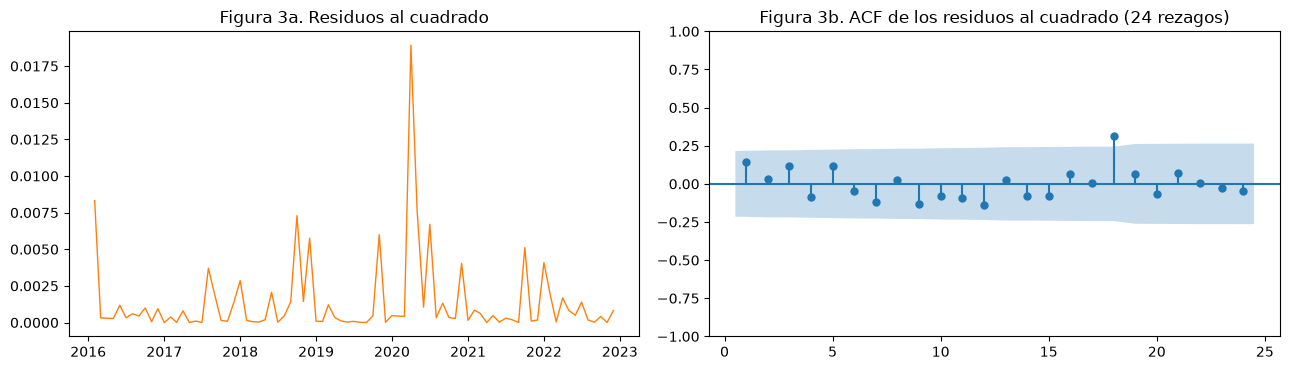

Ljung–Box residuos² (12): Q = 11.53, p = 0.485
ARCH-LM (12):             LM = 9.73, p = 0.639

GARCH(1,1): omega = 0.457 | alpha = 0.066 | beta = 0.442 | persistencia = 0.509 | convergencia = True
Residuos estandarizados: Ljung–Box z² (12) p = 0.654 | ARCH-LM (12) p = 0.832


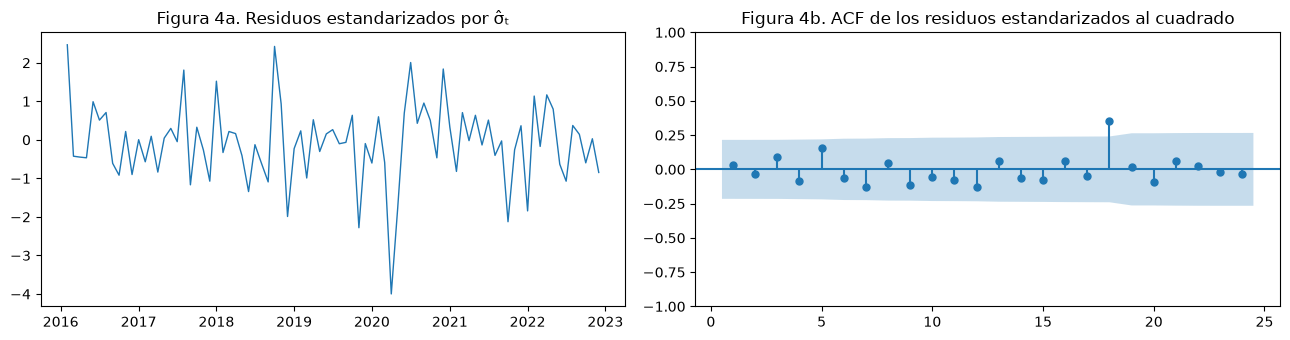

Factor de escala de la desviación estándar condicional: [0.964 0.982 0.991 0.995 0.998 0.999 0.999 1.    1.    1.    1.    1.   ]


In [7]:
# (a) Detección formal sobre los residuos del SARIMA
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(residuos.index, residuos ** 2, lw=1, color="tab:orange")
ax[0].set_title("Figura 3a. Residuos al cuadrado")
plot_acf(residuos ** 2, lags=24, ax=ax[1], zero=False)
ax[1].set_title("Figura 3b. ACF de los residuos al cuadrado (24 rezagos)")
plt.tight_layout(); plt.show()

lb_cuad = acorr_ljungbox(residuos ** 2, lags=[12])
lm_stat, lm_p, _, _ = het_arch(residuos, nlags=12)
print(f"Ljung–Box residuos² (12): Q = {lb_cuad.lb_stat.iloc[0]:.2f}, p = {lb_cuad.lb_pvalue.iloc[0]:.3f}")
print(f"ARCH-LM (12):             LM = {lm_stat:.2f}, p = {lm_p:.3f}")

# (b) GARCH(1,1) por MLE con restricción alpha + beta < 1
g = estimar_garch11(residuos, H)
print(f"\nGARCH(1,1): omega = {g['omega']:.3f} | alpha = {g['alpha']:.3f} | beta = {g['beta']:.3f} | "
      f"persistencia = {g['persistencia']:.3f} | convergencia = {g['convergencia']}")

# (c) Diagnóstico sobre los residuos estandarizados por sigma_t
z = g["residuos_estandarizados"]
lb_z = acorr_ljungbox(z ** 2, lags=[12])
lm_z = het_arch(z, nlags=12)
print(f"Residuos estandarizados: Ljung–Box z² (12) p = {lb_z.lb_pvalue.iloc[0]:.3f} | ARCH-LM (12) p = {lm_z[1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(residuos.index, z, lw=1)
ax[0].set_title("Figura 4a. Residuos estandarizados por σ̂ₜ")
plot_acf(z ** 2, lags=24, ax=ax[1], zero=False)
ax[1].set_title("Figura 4b. ACF de los residuos estandarizados al cuadrado")
plt.tight_layout(); plt.show()

# (d) Bandas GARCH al 95 % en GWh
print("Factor de escala de la desviación estándar condicional:", np.round(g["escala_futura"], 3))
inf_garch = np.exp(media_log - 1.96 * sd_log * g["escala_futura"])
sup_garch = np.exp(media_log + 1.96 * sd_log * g["escala_futura"])
inf_sarima, sup_sarima = np.exp(ic_log.iloc[:, 0]), np.exp(ic_log.iloc[:, 1])

**[BORRADOR] Interpretación.** Aquí la pregunta es si la varianza de los residuos cambia en el tiempo de forma predecible, como en las series financieras, donde a un mes agitado le siguen otros meses agitados (Engle, 1982).

Revisé tres cosas (Notebook S3, §3.3). La ACF de los residuos al cuadrado (Figura 3) no muestra ese patrón: solo el rezago 18 (0,31) sobresale y queda aislado. Ljung-Box sobre los cuadrados da p = 0,485 y ARCH-LM con 12 rezagos da p = 0,639, así que no se rechaza la varianza constante. Este ARCH-LM es el mismo que obtuve en el diagnóstico de la Semana 2, lo que confirma ese resultado.

Igual estimé un GARCH(1,1) (Bollerslev, 1986) por máxima verosimilitud, con la restricción α + β < 1. Obtuve ω = 0,457, α = 0,066 y β = 0,442. Que α sea casi cero tiene sentido: si ARCH-LM no rechaza, un error grande en un mes no anticipa otro grande al mes siguiente. La persistencia (α + β = 0,509) es baja, lejos de los valores cercanos a 1 de las series financieras. Por eso el factor de escala empieza en 0,96 y en dos o tres meses ya vale 1,00, y las bandas GARCH casi coinciden con las del SARIMA.

En los residuos estandarizados por σ̂ₜ (Notebook S3, §3.5; Figura 4) tampoco queda estructura (Ljung-Box p = 0,654; ARCH-LM p = 0,832).

**Conclusión:** no hay volatilidad condicional. Suponer varianza constante, como hace el SARIMA, es adecuado para esta serie.

**[AUTOR] Interpretación de volatilidad** _(máx. 250 palabras)_

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## 3. Contraste con el modelo clásico y consistencia de conclusiones

Tabla 1. Precisión puntual, validación 2023 (GWh)


,RMSE,MAE,ΔRMSE vs SARIMA
SARIMA,7.13,6.68,0.00
"SARIMA + ARFIMA(0,d,0)",7.34,6.93,0.21
Naive estacional,7.26,6.53,0.13


Referencia Sumativa 2 (SARIMA con corrección de sesgo): RMSE = 6.85 GWh, MAE = 6.40 GWh

Tabla 2. Intervalos de predicción al 95 %, validación 2023


,Cobertura,Ancho medio,Meses dentro
SARIMA (varianza constante),1.0,29.445,12/12
"SARIMA + bandas GARCH(1,1)",1.0,29.328,12/12


Errores del SARIMA (real - pronóstico): media = +6.68 GWh | meses con error positivo = 12/12


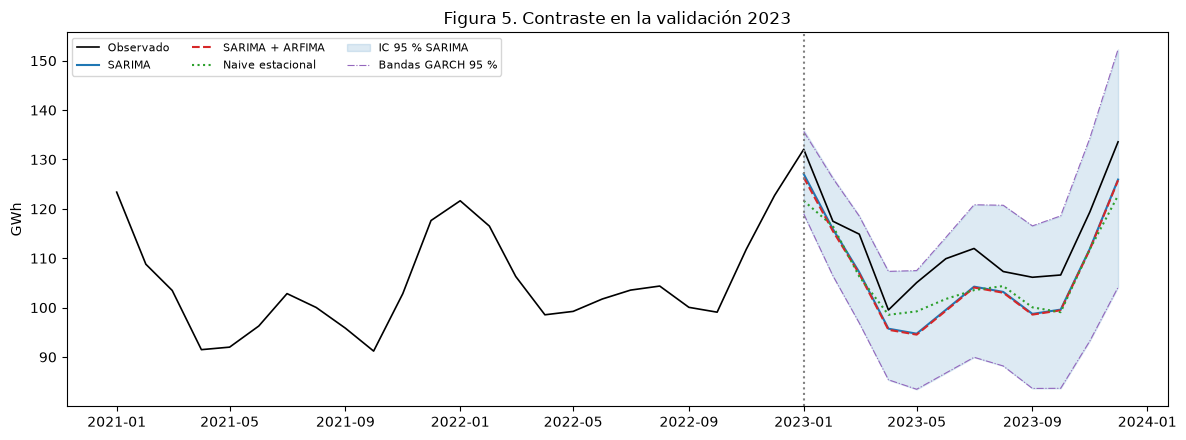

In [8]:
# Precisión puntual (GWh, validación 2023)
tabla_puntual = pd.DataFrame({
    "SARIMA": metricas(y_val, pron_sarima),
    "SARIMA + ARFIMA(0,d,0)": metricas(y_val, pron_arfima),
    "Naive estacional": metricas(y_val, naive),
}).T
tabla_puntual["ΔRMSE vs SARIMA"] = tabla_puntual["RMSE"] - tabla_puntual.loc["SARIMA", "RMSE"]
print("Tabla 1. Precisión puntual, validación 2023 (GWh)")
display(tabla_puntual.round(2))

# Conciliación con la Sumativa 2: allí se volvió a GWh con corrección de sesgo exp(μ + σ²/2)
pron_sarima_sesgo = np.exp(media_log + sd_log ** 2 / 2)
print(f"Referencia Sumativa 2 (SARIMA con corrección de sesgo): RMSE = {metricas(y_val, pron_sarima_sesgo)['RMSE']:.2f} GWh, "
      f"MAE = {metricas(y_val, pron_sarima_sesgo)['MAE']:.2f} GWh")

# Intervalos al 95 %
tabla_intervalos = pd.DataFrame({
    "SARIMA (varianza constante)": cobertura_y_ancho(y_val, inf_sarima, sup_sarima),
    "SARIMA + bandas GARCH(1,1)": cobertura_y_ancho(y_val, inf_garch, sup_garch),
}).T
tabla_intervalos["Meses dentro"] = (tabla_intervalos["Cobertura"] * H).round().astype(int).astype(str) + f"/{H}"
print("\nTabla 2. Intervalos de predicción al 95 %, validación 2023")
display(tabla_intervalos.round(3))

# Sesgo: ¿los errores tienen signo sistemático?
error_sarima = y_val.to_numpy() - pron_sarima.to_numpy()
print(f"Errores del SARIMA (real - pronóstico): media = {error_sarima.mean():+.2f} GWh | "
      f"meses con error positivo = {(error_sarima > 0).sum()}/{H}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y["2021-01":"2023-12"].index, y["2021-01":"2023-12"], color="black", lw=1.2, label="Observado")
ax.plot(y_val.index, pron_sarima, color="tab:blue", label="SARIMA")
ax.plot(y_val.index, pron_arfima, color="tab:red", ls="--", label="SARIMA + ARFIMA")
ax.plot(y_val.index, naive, color="tab:green", ls=":", label="Naive estacional")
ax.fill_between(y_val.index, inf_sarima, sup_sarima, color="tab:blue", alpha=0.15, label="IC 95 % SARIMA")
ax.plot(y_val.index, inf_garch, color="tab:purple", lw=0.8, ls="-.", label="Bandas GARCH 95 %")
ax.plot(y_val.index, sup_garch, color="tab:purple", lw=0.8, ls="-.")
ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":")
ax.set_ylabel("GWh"); ax.set_title("Figura 5. Contraste en la validación 2023")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

**[BORRADOR] Interpretación.** Comparé los modelos en la validación 2023, en GWh (Hyndman y Athanasopoulos, 2021, §5.5 y §5.8). Solo comparé modelos que buscan lo mismo: el ARFIMA con el SARIMA en el pronóstico puntual y el GARCH con el SARIMA en los intervalos. No tiene sentido comparar el AIC de uno con el del otro, porque modelan cosas distintas (Notebook S3, §7).

En el pronóstico puntual (Tabla 1), la corrección ARFIMA no ayuda, sino que empeora un poco: el RMSE sube de 7,13 a 7,34 GWh y el MAE de 6,68 a 6,93 GWh. La diferencia (+0,21 GWh) es cerca del 3 % del error de un mes, y con 12 meses puede ser solo azar (Notebook S3, §4.5). El naive estacional queda muy cerca (RMSE 7,26 GWh). En la Semana 2, el RMSE de 2023 fue 6,85 GWh porque usé corrección de sesgo al volver a GWh; aquí uso exp(μ), como la plantilla, y todos los modelos se tratan igual.

Lo que más me llamó la atención es que los 12 errores del SARIMA son positivos (Figura 5): el modelo subestimó todos los meses de 2023, en +6,68 GWh en promedio. Ese es un problema de nivel, que ni la memoria larga ni la volatilidad pueden corregir.

En los intervalos (Tabla 2), ambos cubren 12 de 12 meses con casi el mismo ancho (29,4 y 29,3 GWh). Con 12 meses, esa diferencia no demuestra nada.

**Conclusión:** ninguna de las dos extensiones mejora al SARIMA.

**[AUTOR] Interpretación del contraste** _(máx. 250 palabras)_

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## 4. Selección del modelo con evidencia cuantitativa

Tabla 3. Pronóstico de validación 2023 del modelo elegido


,Observado (GWh),Pronóstico (GWh),Inferior 95 %,Superior 95 %,Error,Dentro del IC
2023-01,132.06,127.06,118.72,135.98,5.00,True
2023-02,117.49,115.91,106.31,126.37,1.58,True
2023-03,114.88,107.17,96.81,118.64,7.71,True
2023-04,99.53,95.74,85.34,107.40,3.79,True
2023-05,105.07,94.73,83.44,107.53,10.34,True
2023-06,109.91,99.55,86.75,114.24,10.36,True
2023-07,111.98,104.25,89.94,120.84,7.73,True
2023-08,107.31,103.18,88.18,120.74,4.13,True
2023-09,106.15,98.73,83.63,116.56,7.42,True
2023-10,106.61,99.60,83.66,118.58,7.01,True


SARIMA(0, 1, 1)x(0, 1, 1, 12) + covid | AIC = -300.9 | RMSE = 7.134 | MAE = 6.681 | Cobertura = 1.000 | Ancho medio = 29.445


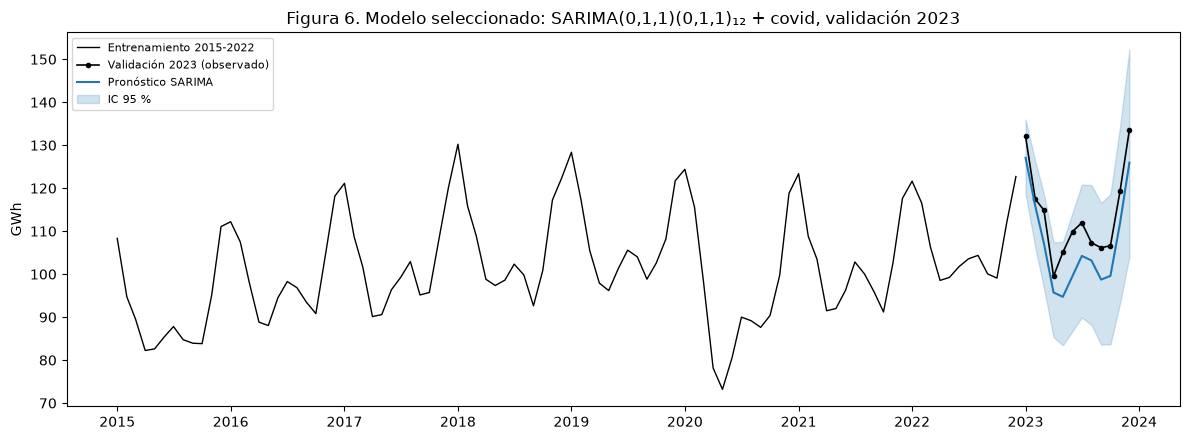

In [9]:
# Modelo elegido: SARIMA(0,1,1)(0,1,1)12 + covid, en log, con su intervalo al 95 % de varianza constante
pronostico_final = pd.DataFrame({
    "Observado (GWh)": y_val,
    "Pronóstico (GWh)": pron_sarima,
    "Inferior 95 %": inf_sarima,
    "Superior 95 %": sup_sarima,
})
pronostico_final["Error"] = pronostico_final["Observado (GWh)"] - pronostico_final["Pronóstico (GWh)"]
pronostico_final["Dentro del IC"] = ((pronostico_final["Observado (GWh)"] >= pronostico_final["Inferior 95 %"]) &
                                     (pronostico_final["Observado (GWh)"] <= pronostico_final["Superior 95 %"]))
pronostico_final.index = pronostico_final.index.strftime("%Y-%m")
print("Tabla 3. Pronóstico de validación 2023 del modelo elegido")
display(pronostico_final.round(2))

resumen = metricas(y_val, pron_sarima) | cobertura_y_ancho(y_val, inf_sarima, sup_sarima)
print(f"SARIMA{ORDEN}x{ORDEN_ESTACIONAL} + covid | AIC = {sarima.aic:.1f} | "
      + " | ".join(f"{k} = {v:.3f}" for k, v in resumen.items()))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(log_train.index, np.exp(log_train), color="black", lw=1, label="Entrenamiento 2015-2022")
ax.plot(y_val.index, y_val, color="black", lw=1.2, marker="o", ms=3, label="Validación 2023 (observado)")
ax.plot(y_val.index, pron_sarima, color="tab:blue", lw=1.5, label="Pronóstico SARIMA")
ax.fill_between(y_val.index, inf_sarima, sup_sarima, color="tab:blue", alpha=0.2, label="IC 95 %")
ax.set_ylabel("GWh"); ax.set_title("Figura 6. Modelo seleccionado: SARIMA(0,1,1)(0,1,1)₁₂ + covid, validación 2023")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**[BORRADOR] Interpretación.** El modelo que paso a la Semana 4 es el mismo de la Semana 2: el **SARIMA(0,1,1)(0,1,1)₁₂ con la variable covid** (modelo B, tipo «airline»), sobre el logaritmo del consumo (Tabla 3 y Figura 6).

No lo mantengo solo porque «no encontré nada», sino por tres resultados:

1. **Memoria larga:** la ACF de los residuos se parece a la de un ruido blanco (Ljung-Box p ≥ 0,10 hasta el rezago 36), y H = 0,652 está dentro de lo que da el R/S para ruido blanco con 83 datos.
2. **Volatilidad:** ARCH-LM p = 0,639, α = 0,066 y persistencia de 0,509.
3. **Contraste:** el ARFIMA sube el RMSE en 0,21 GWh y las bandas GARCH dan la misma cobertura (12/12) con casi el mismo ancho.

Agregar d o (ω, α, β) sería sumar parámetros sin evidencia a favor, que es el error de creer que «el modelo más sofisticado siempre es mejor» (Notebook S3, §5 y §7). Por eso descarto el SARIMA + ARFIMA(0,d,0) y el SARIMA con bandas GARCH(1,1).

En la Semana 4 voy a reestimar este SARIMA con 2015-2023 y pronosticar 2024, con intervalos de varianza constante. Hay que vigilar el sesgo de nivel de 2023 (+6,68 GWh), que debería corregirse en parte al sumar 2023 al entrenamiento, y el MA estacional (−0,981), que sigue en el límite de invertibilidad. Si hace falta mejorar, la opción es agregar regresores como la temperatura (SARIMAX), como ya propuse en la Semana 2.

**[AUTOR] Interpretación de la selección** _(máx. 250 palabras). Este es el modelo que utilizaré en la Semana 4._

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## Conclusiones

**[BORRADOR]**

1. **Memoria larga.** Los residuos del SARIMA no muestran memoria de largo plazo. El H = 0,652 del R/S (d = 0,152) es lo que se espera por el sesgo del método con 83 datos: el 37 % de los ruidos blancos simulados del mismo largo supera ese valor. Además, la ACF no decae lentamente (Ljung-Box p ≥ 0,10 hasta el rezago 36).
2. **Volatilidad.** No hay volatilidad condicional (Ljung-Box sobre cuadrados p = 0,485; ARCH-LM p = 0,639, igual que en la Semana 2). El GARCH(1,1) tiene α = 0,066 y persistencia de 0,509, y sus residuos estandarizados no dejan estructura.
3. **Contraste.** La corrección ARFIMA empeora un poco el RMSE (de 7,13 a 7,34 GWh) y las bandas GARCH no cambian la cobertura (12/12) ni el ancho (≈ 29 GWh). Con 12 meses de validación, ninguna diferencia es relevante.
4. **Selección.** Se mantiene el SARIMA(0,1,1)(0,1,1)₁₂ + covid de la Semana 2. La respuesta a la pregunta de la semana es **negativa, pero con fundamento**: ni la memoria larga ni la volatilidad condicional aportan a esta serie.
5. **Limitaciones.** La validación es de solo 12 meses y el R/S es poco confiable con 83 datos. Solo se probaron las especificaciones mínimas (ARFIMA(0,d,0) y GARCH(1,1)). El margen de mejora real está en el sesgo de nivel de 2023 (+6,68 GWh), que es un problema de la media y se revisará en la Semana 4.

**[AUTOR] Conclusiones**

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._

## Referencias (APA)

Bianchi, F. M. (2023). *Time series analysis with Python* [Repositorio de GitHub]. https://github.com/FilippoMB/python-time-series-handbook

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Granger, C. W. J., y Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *Journal of Time Series Analysis, 1*(1), 15–29. https://doi.org/10.1111/j.1467-9892.1980.tb00297.x

Hosking, J. R. M. (1981). Fractional differencing. *Biometrika, 68*(1), 165–176. https://doi.org/10.1093/biomet/68.1.165

Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers, 116*(1), 770–799.

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., Athanasopoulos, G., Garza, A., Challu, C., Mergenthaler, M., y Olivares, K. G. (2026). *Forecasting: Principles and practice, the Pythonic way*. OTexts. https://otexts.com/fpppy/

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Sheppard, K. (s. f.). *arch: Autoregressive conditional heteroskedasticity models in Python* [Documentación de software]. https://arch.readthedocs.io/

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Notebook de la Sesión 3 y guía de compañía de la Semana 3* [Material de curso]. UNAB Online.

## Declaración de uso de asistentes de IA

**[BORRADOR]** _(ajustar a lo que efectivamente hice antes de entregar)_

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | Sí. Usé Claude (Anthropic), en Claude Code, como apoyo. |
| ¿En qué partes específicas? | En el código de los bloques 1 a 4 sobre la plantilla (incluida la simulación del sesgo del R/S) y en los borradores de texto marcados como [BORRADOR]. Las interpretaciones, la hoja de decisiones y las conclusiones finales son las celdas [AUTOR], que redacté con mis propias palabras. |
| ¿Qué verificó de forma independiente y cómo? | Ejecuté el notebook completo desde un kernel reiniciado y revisé que cada cifra del texto coincidiera con las tablas y figuras. Comprobé que la especificación del SARIMA y su AIC (−300,9) son los mismos de mi Sumativa 2. Contrasté las afirmaciones técnicas con el notebook de la Sesión 3 (§2.2, §2.5, §3.3–§3.5, §4.5, §5 y §7) y con la guía de compañía. |

**[AUTOR] Declaración de uso de asistentes de IA**

> _Pendiente: reescribir con mis propias palabras a partir del borrador anterior, manteniendo las cifras y las citas._